In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, pickle

P = '/content/drive/MyDrive/aqi_project/'
data = pd.read_pickle(P + 'features.pkl')
with open(P + 'state.pkl', 'rb') as f:
    globals().update(pickle.load(f))

print(data.shape, len(features), best_alpha, best_leaf, best_mf)

Mounted at /content/drive
(6542, 111) 94 0.1 20 1.0


**Setup and the run function**

In [5]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, f1_score

pollutants = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
city_cols = [c for c in data.columns if c.startswith('city_')]

sd = data.dropna(subset=['AQI']).copy()
sd['month_t'], sd['dow_t'] = sd['Date'].dt.month, sd['Date'].dt.dayofweek
same_feats = pollutants + ['month_t', 'dow_t'] + city_cols

cat = lambda y: np.digitize(y, [50, 100, 200, 300, 400], right=True)

def run(task, split, prep, smote, model_name, seed):
    if task == 'same':
        df, feats, ycol, dcol = sd, same_feats, 'AQI', 'Date'
        lagc = [f'AQI_lag{k}' for k in range(1, 7)]
    else:
        df, feats, ycol, dcol = data, features, 'target', 'target_date'
        lagc = [f'AQI_lag{k}' for k in range(7)]
    X, y = df[feats].to_numpy(float), df[ycol].to_numpy(float)
    pers = df[lagc].bfill(axis=1).iloc[:, 0].to_numpy(float)
    pers = np.where(np.isnan(pers), np.nanmedian(y), pers)
    y_range = y.max() - y.min()

    if prep == 'before':
        X = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X))
        if smote:
            Z, _ = SMOTE(random_state=seed).fit_resample(np.column_stack([X, pers, y]), cat(y))
            X, pers, y = Z[:, :-2], Z[:, -2], Z[:, -1]
        X_tr, X_te, y_tr, y_te, _, pers_te = train_test_split(X, y, pers, test_size=0.2, random_state=seed)
    else:
        if split == 'random':
            tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=seed)
        else:
            d = df[dcol].values
            tr, te = np.where(d < np.datetime64('2020-01-01'))[0], np.where(d >= np.datetime64('2020-01-01'))[0]
        imp, sc = SimpleImputer(strategy='median'), StandardScaler()
        X_tr = sc.fit_transform(imp.fit_transform(X[tr])); X_te = sc.transform(imp.transform(X[te]))
        y_tr, y_te, pers_te = y[tr], y[te], pers[te]
        if smote:
            Z, _ = SMOTE(random_state=seed).fit_resample(np.column_stack([X_tr, y_tr]), cat(y_tr))
            X_tr, y_tr = Z[:, :-1], Z[:, -1]

    if model_name == 'Ridge':
        model = Ridge(alpha=best_alpha)
    else:
        model = RandomForestRegressor(n_estimators=200, min_samples_leaf=best_leaf,
                                      max_features=best_mf, n_jobs=-1, random_state=seed)
    p = model.fit(X_tr, y_tr).predict(X_te)
    mae, mae_p = mean_absolute_error(y_te, p), mean_absolute_error(y_te, pers_te)
    return {'Accuracy%': (1 - mae / y_range) * 100,
            'PersAccuracy%': (1 - mae_p / y_range) * 100,
            'MAE': mae, 'PersMAE': mae_p,
            'Skill%': (1 - mae / mae_p) * 100,
            'MacroF1': f1_score(cat(y_te), cat(p), average='macro')}

In [6]:
configs = {   # name: (task, split, prep, smote)
    'S0/S1 optimistic':        ('same', 'random', 'before', True),
    'S2 prep on train only':   ('same', 'random', 'train',  True),
    'S3 chronological split':  ('same', 'chrono', 'train',  True),
    'S4 next-day forecast':    ('next', 'chrono', 'train',  True),
    'S5 no SMOTE (main)':      ('next', 'chrono', 'train',  False),
}
rows = []
for name, cfg in configs.items():
    for m in ['Ridge', 'RandomForest']:
        for seed in [0, 1, 2]:
            rows.append({'step': name, 'model': m, 'seed': seed, **run(*cfg, m, seed)})
        print("done:", name, m)

abl = pd.DataFrame(rows)
abl.to_csv('/content/drive/MyDrive/aqi_project/ablation.csv', index=False)

pd.set_option('display.width', 250)
summary = abl.groupby(['step', 'model'], sort=False)[['Accuracy%', 'PersAccuracy%', 'MAE', 'PersMAE', 'Skill%', 'MacroF1']].agg(['mean', 'std']).round(2)
print(summary)

done: S0/S1 optimistic Ridge
done: S0/S1 optimistic RandomForest
done: S2 prep on train only Ridge
done: S2 prep on train only RandomForest
done: S3 chronological split Ridge
done: S3 chronological split RandomForest
done: S4 next-day forecast Ridge
done: S4 next-day forecast RandomForest
done: S5 no SMOTE (main) Ridge
done: S5 no SMOTE (main) RandomForest
                                    Accuracy%       PersAccuracy%          MAE       PersMAE       Skill%       MacroF1      
                                         mean   std          mean   std   mean   std    mean   std   mean   std    mean   std
step                   model                                                                                                 
S0/S1 optimistic       Ridge            96.29  0.10         95.50  0.19  26.61  0.74   32.28  1.39  17.44  4.12    0.62  0.00
                       RandomForest     97.59  0.08         95.50  0.19  17.27  0.58   32.28  1.39  46.47  1.07    0.82  0.01
S2 prep on 

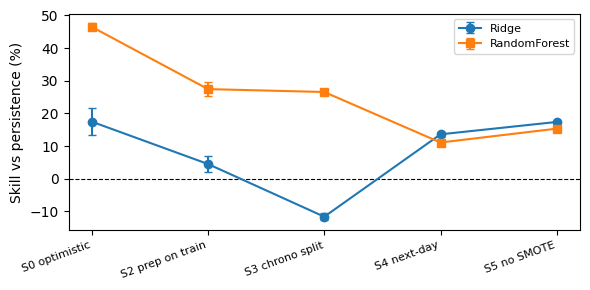

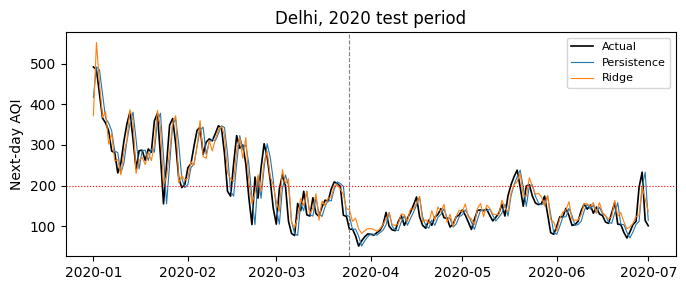

In [7]:
import matplotlib.pyplot as plt

# Figure 2: skill by ablation step
s = abl.groupby(['step', 'model'], sort=False)['Skill%'].agg(['mean', 'std']).reset_index()
steps = list(configs.keys())
xlabels = ['S0 optimistic', 'S2 prep on train', 'S3 chrono split', 'S4 next-day', 'S5 no SMOTE']
fig, ax = plt.subplots(figsize=(6, 3))
for m, mk in [('Ridge', 'o'), ('RandomForest', 's')]:
    d = s[s.model == m].set_index('step').loc[steps]
    ax.errorbar(range(5), d['mean'], yerr=d['std'], marker=mk, capsize=3, label=m)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.set_xticks(range(5)); ax.set_xticklabels(xlabels, rotation=20, ha='right', fontsize=8)
ax.set_ylabel('Skill vs persistence (%)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(P + 'fig_ablation_skill.png', dpi=200); plt.show()

# Figure 3: Delhi, 2020 test period
test = data[data['target_date'] >= '2020-01-01']
dl = test['City'].values == 'Delhi'
t = test['target_date'].values[dl]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, test['target'].values[dl], 'k', lw=1.2, label='Actual')
ax.plot(t, np.asarray(test_preds['Persistence'])[dl], lw=0.8, label='Persistence')
ax.plot(t, np.asarray(test_preds['Ridge'])[dl], lw=0.8, label='Ridge')
ax.axvline(np.datetime64('2020-03-25'), color='grey', ls='--', lw=0.8)
ax.axhline(200, color='r', ls=':', lw=0.8)
ax.set_ylabel('Next-day AQI'); ax.set_title('Delhi, 2020 test period'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(P + 'fig_delhi_test.png', dpi=200); plt.show()